In [ ]:
# Traduccion de las Columnas
[
 'fecha',
 'dia_semana',
 'hora',
 'estado',
 'id_carretera',
 'kilometro',
 'ciudad',
 'causa_del_accidente',
 'tipo_de_accidente',
 'condicion_de_las_victimas',
 'marca de tiempo del clima',
 'sentido_de_la_via',
 'condicion_climatica',
 'tipo_de_via',
 'delimitacion_de_la_via',
 'personas',
 'muertes',
 'heridos_leves',
 'heridos_graves',
 'ilesos',
 'ignorados',
 'total_heridos',
 'vehiculos_involucrados',
 'latitud',
 'longitud',
 'regional',
 'comisaria'
]

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv("C:/Users/herna/Downloads/accidents_2017_to_2023_english.csv")
df.head()

,inverse_data,week_day,hour,state,road_id,km,city,cause_of_accident,type_of_accident,victims_condition,weather_timestamp,road_direction,wheather_condition,road_type,road_delineation,people,deaths,slightly_injured,severely_injured,uninjured,ignored,total_injured,vehicles_involved,latitude,longitude,regional,police_station
0,2017-01-01,sunday,01:45:00,RS,116.0,"34,9",VACARIA,Mechanical loss/defect of vehicle,Rear-end collision,With injured victims,Night,Decreasing,Clear sky,Simple,Straight,6,0,4,0,2,0,4,2,-28.50712,-50.94118,SPRF-RS,DEL05-RS
1,2017-01-01,sunday,01:00:00,PR,376.0,636,TIJUCAS DO SUL,Incompatible velocity,Run-off-road,With dead victims,Night,Increasing,Drizzle,Double,Curve,2,1,0,0,1,0,0,2,-25.75400,-49.12660,SPRF-PR,DEL01-PR
2,2017-01-01,sunday,04:40:00,BA,101.0,65,ENTRE RIOS,Driver was sleeping,Head-on collision,With dead victims,Sunrise,Decreasing,Cloudy,Simple,Curve,5,1,1,1,2,0,2,2,-11.96180,-38.09530,SPRF-BA,DEL01-BA
3,2017-01-01,sunday,06:30:00,PA,316.0,"72,5",CASTANHAL,Driver's lack of attention to conveyance,Side impact collision,With dead victims,Sunrise,Decreasing,Clear sky,Simple,Straight,4,1,0,0,3,0,0,3,-1.28998,-47.83483,SPRF-PA,DEL01-PA
4,2017-01-01,sunday,09:00:00,GO,20.0,"220,5",POSSE,Road's defect,Collision with fixed object,With injured victims,Day,Decreasing,Clear sky,Simple,Temporary Detour,3,0,2,1,0,0,3,1,-14.14221,-46.32259,SPRF-DF,DEL02-DF


In [3]:
# Estructura, tamaño del dataframe y nombre de las columnas

df.info()
df.shape
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463152 entries, 0 to 463151
Data columns (total 27 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   inverse_data        463152 non-null  object 
 1   week_day            463152 non-null  object 
 2   hour                463152 non-null  object 
 3   state               463152 non-null  object 
 4   road_id             462162 non-null  float64
 5   km                  462162 non-null  object 
 6   city                463152 non-null  object 
 7   cause_of_accident   463152 non-null  object 
 8   type_of_accident    463152 non-null  object 
 9   victims_condition   463152 non-null  object 
 10  weather_timestamp   463152 non-null  object 
 11  road_direction      463152 non-null  object 
 12  wheather_condition  463152 non-null  object 
 13  road_type           463152 non-null  object 
 14  road_delineation    463152 non-null  object 
 15  people              463152 non-nul

Index(['inverse_data', 'week_day', 'hour', 'state', 'road_id', 'km', 'city',
       'cause_of_accident', 'type_of_accident', 'victims_condition',
       'weather_timestamp', 'road_direction', 'wheather_condition',
       'road_type', 'road_delineation', 'people', 'deaths', 'slightly_injured',
       'severely_injured', 'uninjured', 'ignored', 'total_injured',
       'vehicles_involved', 'latitude', 'longitude', 'regional',
       'police_station'],
      dtype='object')

In [4]:
# Tipo de Datos de cada columna
df.dtypes

inverse_data           object
week_day               object
hour                   object
state                  object
road_id               float64
km                     object
city                   object
cause_of_accident      object
type_of_accident       object
victims_condition      object
weather_timestamp      object
road_direction         object
wheather_condition     object
road_type              object
road_delineation       object
people                  int64
deaths                  int64
slightly_injured        int64
severely_injured        int64
uninjured               int64
ignored                 int64
total_injured           int64
vehicles_involved       int64
latitude              float64
longitude             float64
regional               object
police_station         object
dtype: object

In [5]:
# Valores unicos de cada columna y la cantidad de veces que aparecen
print(
    df['wheather_condition'].value_counts(),
    df['week_day'].value_counts(),
    df['hour'].value_counts(),
    df['regional'].value_counts(),
    df['police_station'].value_counts(),
    df['state'].value_counts()
)

wheather_condition
Clear sky    269961
Cloudy        78677
Rainy         54136
Sunny         32769
Drizzle       15986
Ignored        6674
Fog            3956
Windy           967
Hail             18
Snowy             8
Name: count, dtype: int64 week_day
saturday     77133
sunday       76960
friday       71435
monday       62816
thursday     60329
wednesday    57878
tuesday      56601
Name: count, dtype: int64 hour
19:00:00    6686
18:00:00    6573
18:30:00    6260
17:00:00    5538
16:00:00    5124
            ... 
01:17:00       3
03:39:00       3
04:09:00       3
04:04:00       1
02:36:00       1
Name: count, Length: 1440, dtype: int64 regional
SPRF-MG    61177
SPRF-SC    55722
SPRF-PR    52576
SPRF-RS    32464
SPRF-RJ    32231
SPRF-SP    30694
SPRF-BA    23837
SPRF-PE    19124
SPRF-ES    17308
SPRF-MT    16196
SPRF-GO    15801
SPRF-DF    13583
SPRF-MS    10909
SPRF-CE    10757
SPRF-RO    10403
SPRF-PB    10294
SPRF-RN     9145
SPRF-PI     8711
SPRF-MA     7860
SPRF-PA     6797
SPRF-A

In [6]:
# Estadisticas descriptivas de cada columna
df[['deaths', 'total_injured', 'severely_injured']].describe()

,deaths,total_injured,severely_injured
count,463152.000000,463152.000000,463152.000000
mean,0.079235,1.094999,0.259530
std,0.332169,1.205351,0.602814
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,1.000000,0.000000
75%,0.000000,1.000000,0.000000
max,21.000000,66.000000,31.000000


# LIMPIEZA DE DATOS

In [7]:
# Eliminamos las siguientes columnas 
df = df.drop(['inverse_data', 'weather_timestamp', 'road_id' ,'km', 'city', 'regional', 'police_station'], axis=1)

In [8]:
# Para saber la cantidad de valores nulos en el DataFrame
df.isnull().sum()

week_day              0
hour                  0
state                 0
cause_of_accident     0
type_of_accident      0
victims_condition     0
road_direction        0
wheather_condition    0
road_type             0
road_delineation      0
people                0
deaths                0
slightly_injured      0
severely_injured      0
uninjured             0
ignored               0
total_injured         0
vehicles_involved     0
latitude              0
longitude             0
dtype: int64

In [9]:
# Eliminamos los valores nulos
# df = df.dropna()

In [9]:
# Descompone el tiempo en hora y minuto, en 2 columnas.
#dt = pd.to_datetime(df['hour'])
#df['hour_num'] = dt.dt.hour
#df['minute'] = dt.dt.minute

# Cambia el tipo de dato de hour a datetime
df['hour_num'] = pd.to_datetime(df['hour']).dt.hour

C:\Users\herna\AppData\Local\Temp\ipykernel_5880\980307460.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['hour_num'] = pd.to_datetime(df['hour']).dt.hour


In [10]:
# Eliminación de la columna original de hora
df = df.drop(['hour'], axis=1)

In [11]:
# Es una función que clasifica cada accidente según su gravedad.

def severity(row):
    if row['deaths'] > 0:
        return 2  # fatal
    elif row['severely_injured'] > 0:
        return 1  # grave
    else:
        return 0  # leve

df['severity'] = df.apply(severity, axis=1)

# 2 --> fatal
# 1 --> grave
# 0 --> leve


In [12]:
# Convertir estas columnas en categorias

categorical_cols = [
    'week_day',
    'wheather_condition',
    'road_type',
    'road_direction',
    'road_delineation',
    'state',
    'cause_of_accident',
    'type_of_accident'
]

for col in categorical_cols:
    df[col] = df[col].astype('category')

In [13]:
df.head()

,week_day,state,cause_of_accident,type_of_accident,victims_condition,road_direction,wheather_condition,road_type,road_delineation,people,deaths,slightly_injured,severely_injured,uninjured,ignored,total_injured,vehicles_involved,latitude,longitude,hour_num,severity
0,sunday,RS,Mechanical loss/defect of vehicle,Rear-end collision,With injured victims,Decreasing,Clear sky,Simple,Straight,6,0,4,0,2,0,4,2,-28.50712,-50.94118,1,0
1,sunday,PR,Incompatible velocity,Run-off-road,With dead victims,Increasing,Drizzle,Double,Curve,2,1,0,0,1,0,0,2,-25.75400,-49.12660,1,2
2,sunday,BA,Driver was sleeping,Head-on collision,With dead victims,Decreasing,Cloudy,Simple,Curve,5,1,1,1,2,0,2,2,-11.96180,-38.09530,4,2
3,sunday,PA,Driver's lack of attention to conveyance,Side impact collision,With dead victims,Decreasing,Clear sky,Simple,Straight,4,1,0,0,3,0,0,3,-1.28998,-47.83483,6,2
4,sunday,GO,Road's defect,Collision with fixed object,With injured victims,Decreasing,Clear sky,Simple,Temporary Detour,3,0,2,1,0,0,3,1,-14.14221,-46.32259,9,1


In [14]:
df.dtypes

week_day              category
state                 category
cause_of_accident     category
type_of_accident      category
victims_condition       object
road_direction        category
wheather_condition    category
road_type             category
road_delineation      category
people                   int64
deaths                   int64
slightly_injured         int64
severely_injured         int64
uninjured                int64
ignored                  int64
total_injured            int64
vehicles_involved        int64
latitude               float64
longitude              float64
hour_num                 int32
severity                 int64
dtype: object

# Definicion del Modelo

In [15]:
# Instalamos LightGBM
!pip install lightgbm

In [16]:
# Instalamos xgboost
!pip install xgboost

In [17]:
# 1. Crear dataset para modelado (sin fuga de información)
df_model = df.drop([
    'deaths',
    'severely_injured',
    'slightly_injured',
    'total_injured',
    'victims_condition' 
], axis=1)

In [18]:
# Separamos Variables

X = df_model.drop(['severity'], axis=1)
y = df_model['severity']

In [19]:
# Codificamos Categorias
X = pd.get_dummies(X, drop_first=True)

In [20]:
# Entrenamiento / Prueba

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# stratify=y = MUY importante (por el desbalance)

In [21]:
# 4. Calcular pesos 
# from sklearn.utils.class_weight import compute_sample_weight

# sample_weights = compute_sample_weight(
#    class_weight='balanced',
#    y=y_train
# )

# Definir pesos manuales por clase
weights = y_train.map({
    0: 1,    # leve
    1: 2.7,    # grave
    2: 3     # fatal
})

In [22]:
# Modelo XGBoost

import xgboost as xgb

model_xgb = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    eval_metric='mlogloss',
    random_state=42
)

model_xgb.fit(X_train, y_train, sample_weight = weights)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'


In [24]:
# Prediccion
y_pred = model_xgb.predict(X_test)

In [25]:
# Metricas para saber precision

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.78      0.82     68451
           1       0.35      0.51      0.42     17911
           2       0.44      0.32      0.37      6269

    accuracy                           0.70     92631
   macro avg       0.55      0.53      0.53     92631
weighted avg       0.73      0.70      0.71     92631



In [26]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

[[53638 13670  1143]
 [ 7432  9054  1425]
 [ 1308  2981  1980]]


<Figure size 700x600 with 0 Axes>

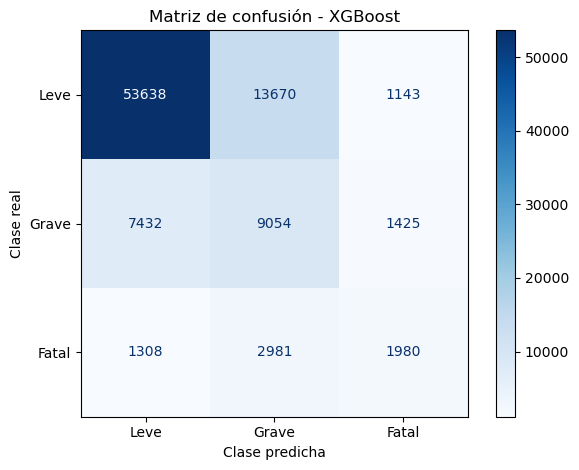

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

# Etiquetas de clases
labels = ['Leve', 'Grave', 'Fatal']

# Graficar
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

plt.figure(figsize=(7, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - XGBoost')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')
plt.tight_layout()

# Exportar imagen
plt.savefig('matriz_confusion_xgboost.png', dpi=300, bbox_inches='tight')

plt.show()

# Modelo LightGBM

In [28]:
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix

# Modelo LightGBM
model_lgbm = lgb.LGBMClassifier(
    objective='multiclass',
    num_class=3,
    random_state=42
)

# Entrenar con los mismos pesos
model_lgbm.fit(
    X_train,
    y_train,
    sample_weight=weights
)

# Predicción
y_pred_lgbm = model_lgbm.predict(X_test)

# Métricas
print(classification_report(y_test, y_pred_lgbm))
print(confusion_matrix(y_test, y_pred_lgbm))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002451 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 963
[LightGBM] [Info] Number of data points in the train set: 370521, number of used features: 156
[LightGBM] [Info] Start training from score -0.683720
[LightGBM] [Info] Start training from score -1.031164
[LightGBM] [Info] Start training from score -1.975641
              precision    recall  f1-score   support

           0       0.86      0.78      0.82     68451
           1       0.35      0.52      0.42     17911
           2       0.44      0.31      0.37      6269

    accuracy                           0.70     92631
   macro avg       0.55      0.54      0.53     92631
weighted avg       0.74      0.70      0.71     92631

[[53261 14109  1081]
 [

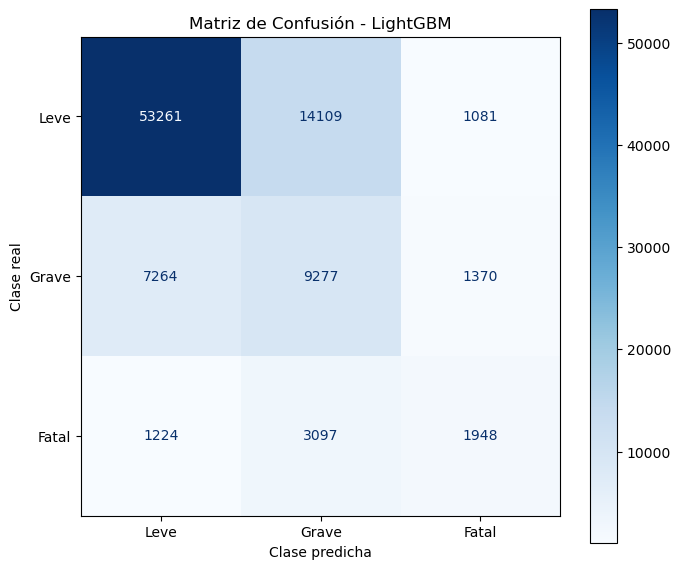

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Crear matriz de confusión (usar y_pred_lgbm)
cm = confusion_matrix(y_test, y_pred_lgbm)

# 2. Etiquetas
labels = ['Leve', 'Grave', 'Fatal']

# 3. Graficar
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', values_format='d', ax=ax)

plt.title('Matriz de Confusión - LightGBM')
plt.xlabel('Clase predicha')
plt.ylabel('Clase real')

plt.tight_layout()

# 4. Guardar imagen
plt.savefig('matriz_confusion_lightgbm.png', dpi=300)

# 5. Mostrar
plt.show()

# SHAP

In [29]:
!pip install shap

   ---------------------------------------- 0.0/555.9 kB ? eta -:--:--
   ---------------------------------------- 555.9/555.9 kB 7.3 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [30]:
import shap
import matplotlib.pyplot as plt

# Tomar muestra (para que no sea pesado)
X_shap = X_test.sample(n=2000, random_state=42)

In [31]:
explainer_lgbm = shap.TreeExplainer(model_lgbm)

shap_values_lgbm = explainer_lgbm.shap_values(X_shap)

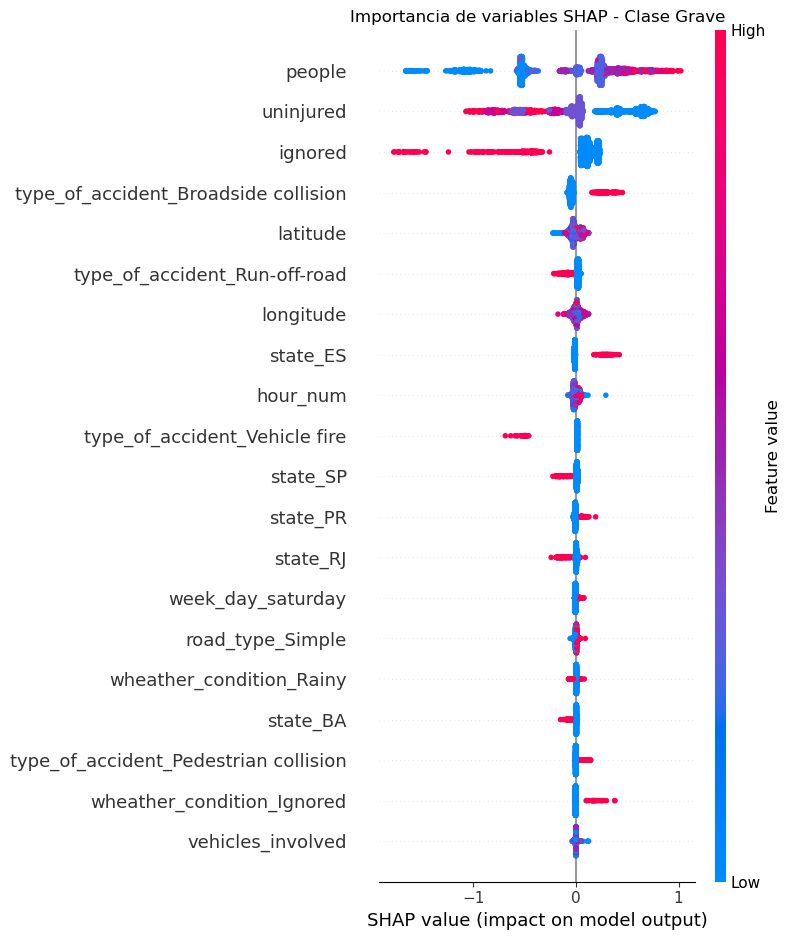

In [32]:
shap.summary_plot(
    shap_values_lgbm[:, :, 1],  # clase grave
    X_shap,
    show=False
)

plt.title("Importancia de variables SHAP - Clase Grave")
plt.tight_layout()
plt.savefig("shap_grave_lightgbm.png", dpi=300, bbox_inches="tight")
plt.show()

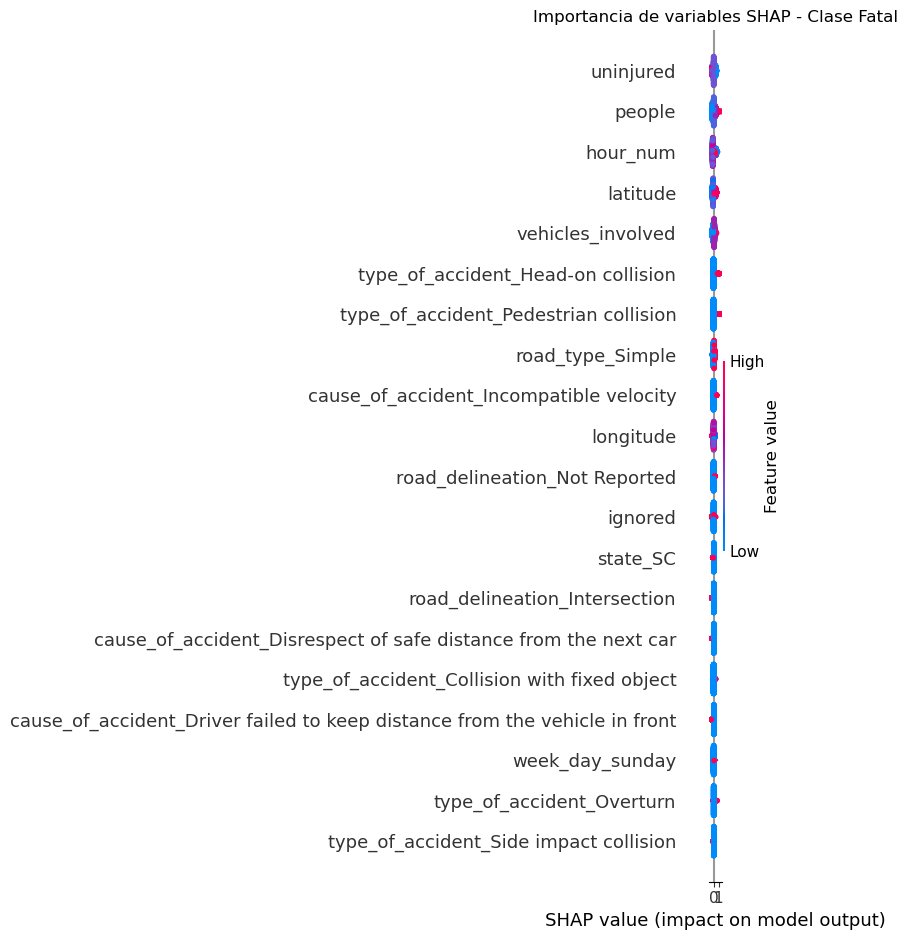

In [33]:
shap.summary_plot(
    shap_values_lgbm[:, :, 2],  # clase fatal
    X_shap,
    show=False
)

plt.title("Importancia de variables SHAP - Clase Fatal")
plt.tight_layout()
plt.savefig("shap_fatal_lightgbm.png", dpi=300, bbox_inches="tight")
plt.show()

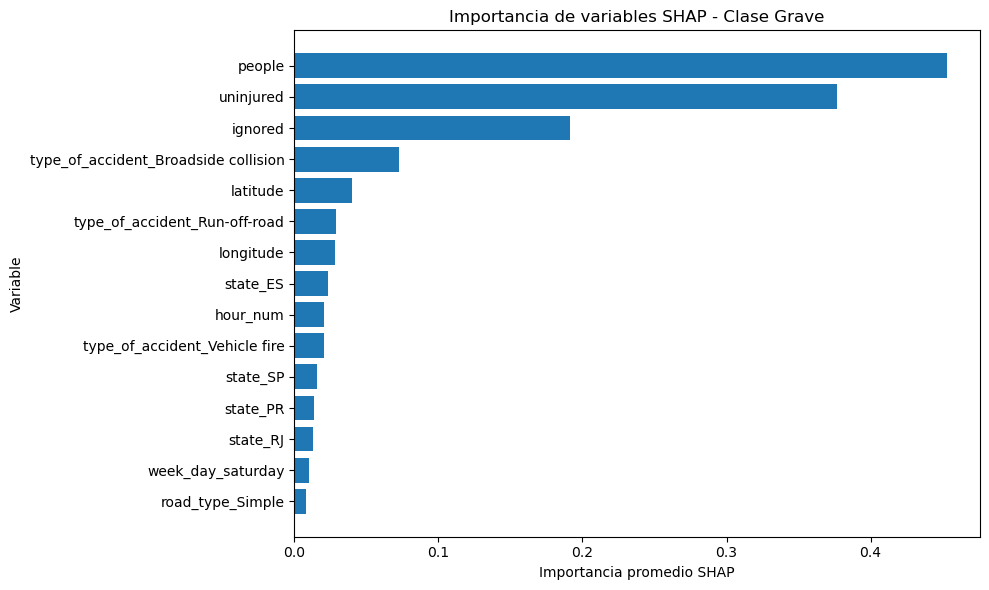

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importancia promedio absoluta para clase grave
shap_importance_grave = np.abs(shap_values_lgbm[:, :, 1]).mean(axis=0)

df_shap_grave = pd.DataFrame({
    'Variable': X_shap.columns,
    'Importancia': shap_importance_grave
}).sort_values(by='Importancia', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(df_shap_grave['Variable'], df_shap_grave['Importancia'])
plt.gca().invert_yaxis()
plt.title('Importancia de variables SHAP - Clase Grave')
plt.xlabel('Importancia promedio SHAP')
plt.ylabel('Variable')
plt.tight_layout()

plt.savefig('shap_bar_grave_lightgbm.png', dpi=300, bbox_inches='tight')
plt.show()

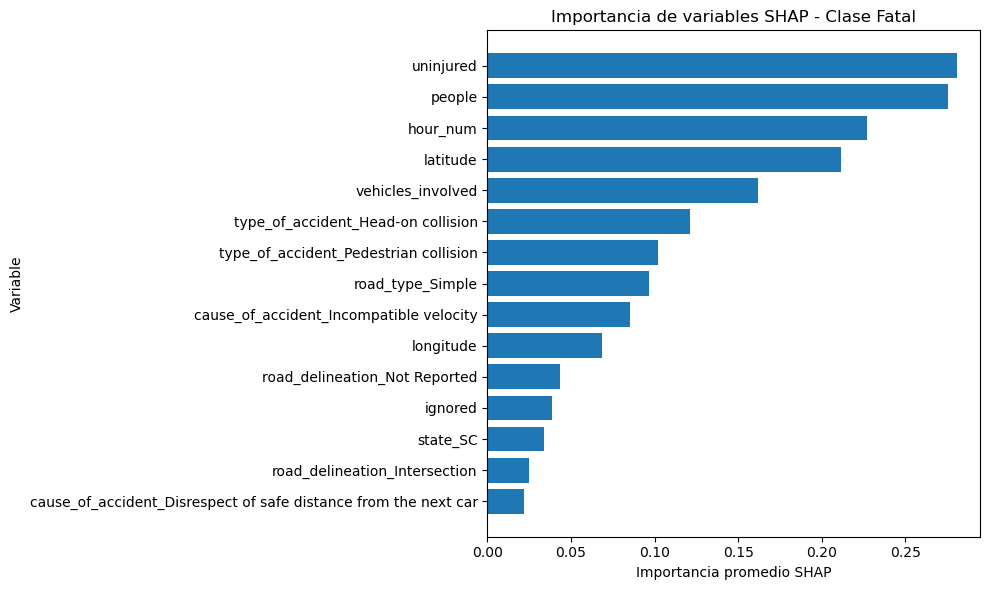

In [35]:
# Importancia promedio absoluta para clase fatal
shap_importance_fatal = np.abs(shap_values_lgbm[:, :, 2]).mean(axis=0)

df_shap_fatal = pd.DataFrame({
    'Variable': X_shap.columns,
    'Importancia': shap_importance_fatal
}).sort_values(by='Importancia', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(df_shap_fatal['Variable'], df_shap_fatal['Importancia'])
plt.gca().invert_yaxis()
plt.title('Importancia de variables SHAP - Clase Fatal')
plt.xlabel('Importancia promedio SHAP')
plt.ylabel('Variable')
plt.tight_layout()

plt.savefig('shap_bar_fatal_lightgbm.png', dpi=300, bbox_inches='tight')
plt.show()

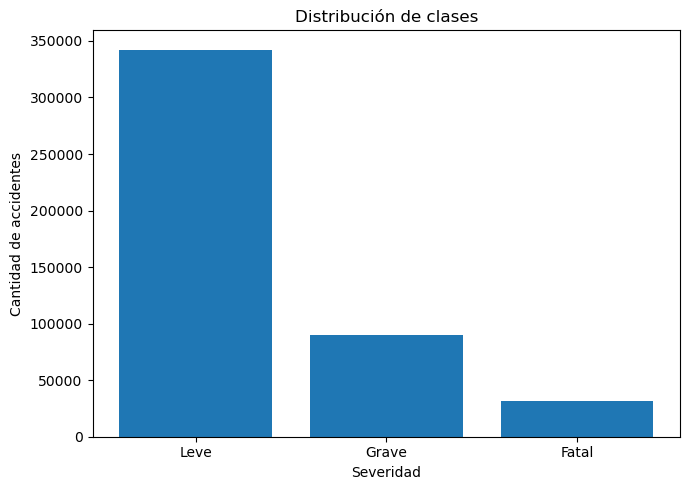

In [36]:
import matplotlib.pyplot as plt

# Contar clases
class_counts = df['severity'].value_counts().sort_index()

# Etiquetas
labels = ['Leve', 'Grave', 'Fatal']

# Gráfico
plt.figure(figsize=(7,5))

plt.bar(labels, class_counts)

plt.title('Distribución de clases')
plt.xlabel('Severidad')
plt.ylabel('Cantidad de accidentes')

plt.tight_layout()

# Guardar
plt.savefig('distribucion_clases.png', dpi=300)

plt.show()

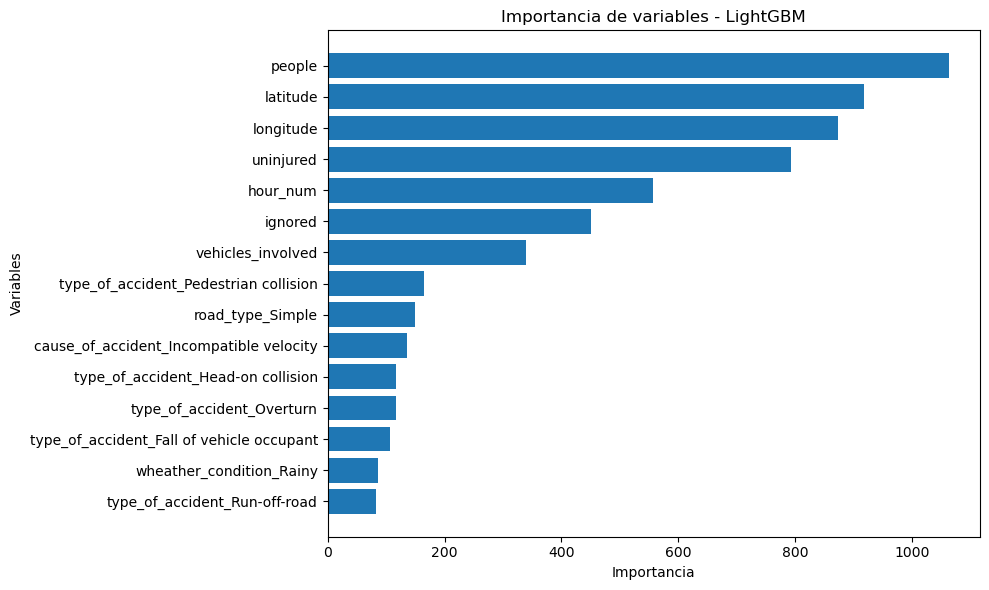

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Obtener importancia
importance = model_lgbm.feature_importances_

# Crear dataframe
feature_importance = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': importance
})

# Ordenar
feature_importance = feature_importance.sort_values(
    by='Importancia',
    ascending=False
).head(15)

# Graficar
plt.figure(figsize=(10,6))

plt.barh(
    feature_importance['Variable'],
    feature_importance['Importancia']
)

plt.gca().invert_yaxis()

plt.title('Importancia de variables - LightGBM')
plt.xlabel('Importancia')
plt.ylabel('Variables')

plt.tight_layout()

plt.savefig('feature_importance_lightgbm.png', dpi=300)

plt.show()

In [37]:
!pip install folium


   ---------------------------------------- 2/2 [folium]



In [38]:
import folium
from folium.plugins import HeatMap

# Filtrar coordenadas válidas aproximadas de Brasil
df_map = df[['latitude', 'longitude']].dropna()

df_map = df_map[
    (df_map['latitude'] >= -35) & (df_map['latitude'] <= 6) &
    (df_map['longitude'] >= -75) & (df_map['longitude'] <= -30)
]

print(df_map.shape)
print(df_map[['latitude', 'longitude']].describe())

# Crear mapa centrado en Brasil
mapa = folium.Map(
    location=[-14.2350, -51.9253],
    zoom_start=4,
    tiles='CartoDB positron'
)

# Agregar heatmap más visible
HeatMap(
    data=df_map[['latitude', 'longitude']].values.tolist(),
    radius=15,
    blur=10,
    min_opacity=0.4,
    max_zoom=8
).add_to(mapa)

mapa.save("heatmap_accidentes.html")
mapa

(463098, 2)
            latitude      longitude
count  463098.000000  463098.000000
mean      -18.886844     -46.649232
std         7.772366       6.172889
min       -33.706080     -72.119380
25%       -25.331120     -50.302940
50%       -20.420375     -47.808310
75%       -12.828340     -42.643340
max         4.461419     -34.000000


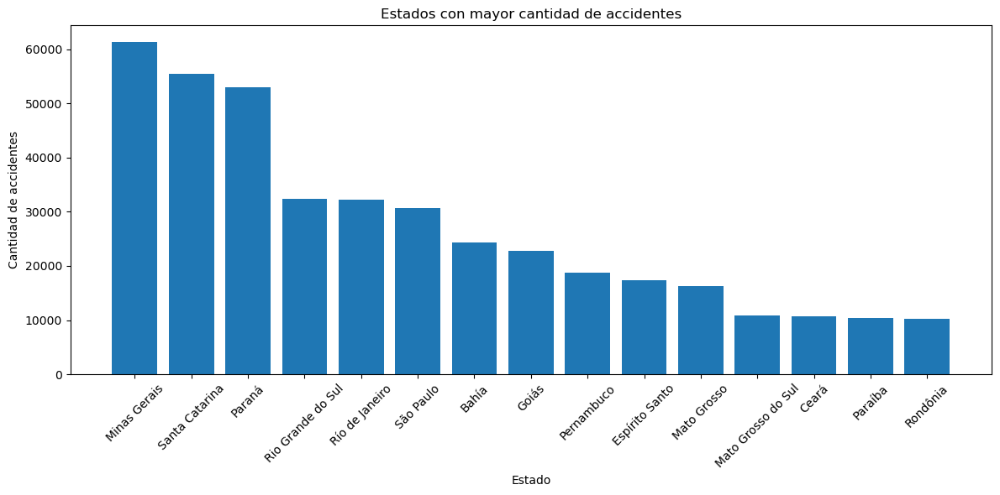

In [39]:
import matplotlib.pyplot as plt

# Diccionario de estados de Brasil
estados_brasil = {
    'AC': 'Acre',
    'AL': 'Alagoas',
    'AP': 'Amapá',
    'AM': 'Amazonas',
    'BA': 'Bahía',
    'CE': 'Ceará',
    'DF': 'Distrito Federal',
    'ES': 'Espírito Santo',
    'GO': 'Goiás',
    'MA': 'Maranhão',
    'MT': 'Mato Grosso',
    'MS': 'Mato Grosso do Sul',
    'MG': 'Minas Gerais',
    'PA': 'Pará',
    'PB': 'Paraíba',
    'PR': 'Paraná',
    'PE': 'Pernambuco',
    'PI': 'Piauí',
    'RJ': 'Río de Janeiro',
    'RN': 'Rio Grande do Norte',
    'RS': 'Rio Grande do Sul',
    'RO': 'Rondônia',
    'RR': 'Roraima',
    'SC': 'Santa Catarina',
    'SP': 'São Paulo',
    'SE': 'Sergipe',
    'TO': 'Tocantins'
}

# Contar accidentes por estado
accidentes_estado = df['state'].value_counts().head(15)

# Reemplazar siglas por nombres completos
nombres_estados = [
    estados_brasil.get(sigla, sigla)
    for sigla in accidentes_estado.index
]

# Crear gráfico
plt.figure(figsize=(12,6))

plt.bar(nombres_estados, accidentes_estado.values)

plt.title('Estados con mayor cantidad de accidentes')
plt.xlabel('Estado')
plt.ylabel('Cantidad de accidentes')

plt.xticks(rotation=45)

plt.tight_layout()

# Guardar imagen
plt.savefig('accidentes_por_estado.png', dpi=300, bbox_inches='tight')

plt.show()

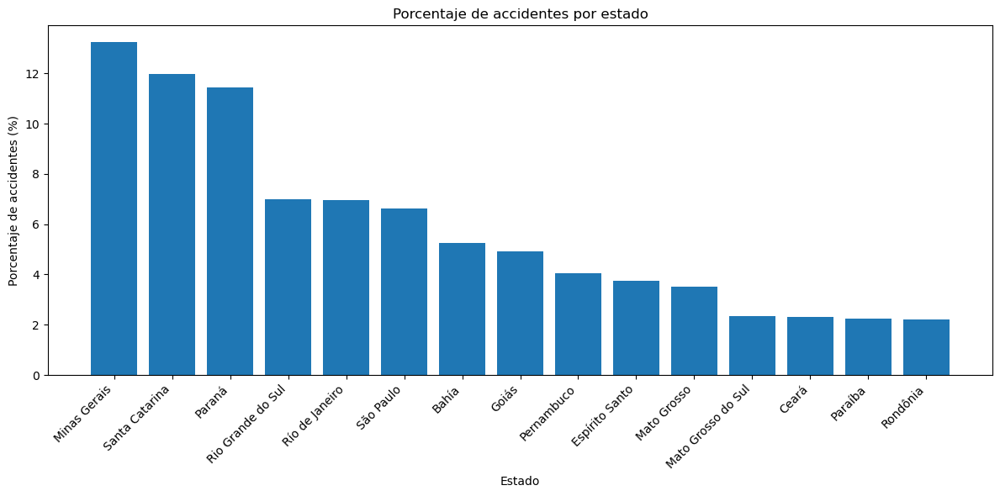

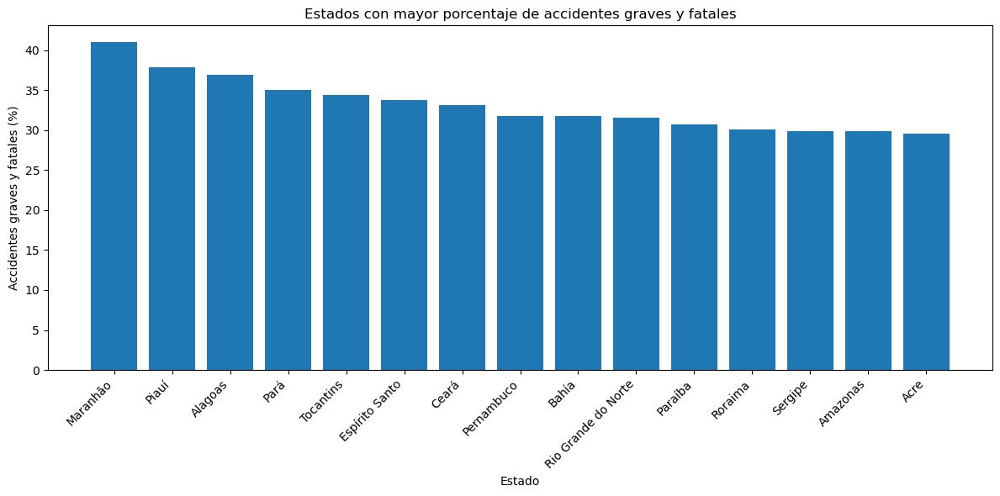

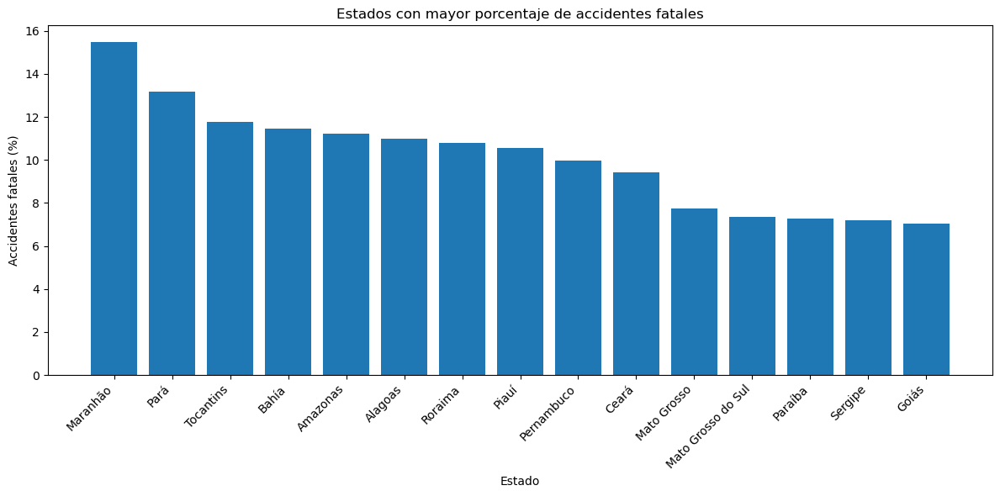

              state_name wheather_condition  cantidad
120         Minas Gerais          Clear sky     34271
130               Paraná          Clear sky     28332
230       Santa Catarina          Clear sky     26793
190    Rio Grande do Sul          Clear sky     19062
220       Río de Janeiro          Clear sky     18085
250            São Paulo          Clear sky     15928
80                 Goiás          Clear sky     15234
40                 Bahía          Clear sky     14482
160           Pernambuco          Clear sky     11359
100          Mato Grosso          Clear sky     10461
70        Espírito Santo          Clear sky      9751
50                 Ceará          Clear sky      7794
110   Mato Grosso do Sul          Clear sky      7491
180  Rio Grande do Norte          Clear sky      6564
200             Rondônia          Clear sky      6560
140              Paraíba          Clear sky      6429
170                Piauí          Clear sky      6108
90              Maranhão    

C:\Users\herna\AppData\Local\Temp\ipykernel_5880\346548095.py:111: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['state_name', 'wheather_condition'])


In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# Diccionario de estados de Brasil
estados_brasil = {
    'AC': 'Acre', 'AL': 'Alagoas', 'AP': 'Amapá', 'AM': 'Amazonas',
    'BA': 'Bahía', 'CE': 'Ceará', 'DF': 'Distrito Federal',
    'ES': 'Espírito Santo', 'GO': 'Goiás', 'MA': 'Maranhão',
    'MT': 'Mato Grosso', 'MS': 'Mato Grosso do Sul',
    'MG': 'Minas Gerais', 'PA': 'Pará', 'PB': 'Paraíba',
    'PR': 'Paraná', 'PE': 'Pernambuco', 'PI': 'Piauí',
    'RJ': 'Río de Janeiro', 'RN': 'Rio Grande do Norte',
    'RS': 'Rio Grande do Sul', 'RO': 'Rondônia', 'RR': 'Roraima',
    'SC': 'Santa Catarina', 'SP': 'São Paulo', 'SE': 'Sergipe',
    'TO': 'Tocantins'
}

# Crear copia para análisis
df_geo = df.copy()

# Nombre completo del estado
df_geo['state_name'] = df_geo['state'].astype(str).map(estados_brasil)

# =========================
# 1. Porcentaje de accidentes por estado
# =========================

accidentes_estado_pct = (
    df_geo['state_name']
    .value_counts(normalize=True)
    .mul(100)
    .head(15)
)

plt.figure(figsize=(12,6))
plt.bar(accidentes_estado_pct.index, accidentes_estado_pct.values)
plt.title('Porcentaje de accidentes por estado')
plt.xlabel('Estado')
plt.ylabel('Porcentaje de accidentes (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('porcentaje_accidentes_por_estado.png', dpi=300, bbox_inches='tight')
plt.show()


# =========================
# 2. Porcentaje de accidentes graves/fatales por estado
# =========================
# severity: 0 = leve, 1 = grave, 2 = fatal

resumen_estado = (
    df_geo
    .groupby('state_name')
    .agg(
        total_accidentes=('severity', 'count'),
        graves=('severity', lambda x: (x == 1).sum()),
        fatales=('severity', lambda x: (x == 2).sum())
    )
)

resumen_estado['pct_graves'] = resumen_estado['graves'] / resumen_estado['total_accidentes'] * 100
resumen_estado['pct_fatales'] = resumen_estado['fatales'] / resumen_estado['total_accidentes'] * 100
resumen_estado['pct_graves_fatales'] = (
    (resumen_estado['graves'] + resumen_estado['fatales'])
    / resumen_estado['total_accidentes'] * 100
)

# Top 15 por porcentaje de graves + fatales
top_graves_fatales = resumen_estado.sort_values(
    by='pct_graves_fatales',
    ascending=False
).head(15)

plt.figure(figsize=(12,6))
plt.bar(top_graves_fatales.index, top_graves_fatales['pct_graves_fatales'])
plt.title('Estados con mayor porcentaje de accidentes graves y fatales')
plt.xlabel('Estado')
plt.ylabel('Accidentes graves y fatales (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('porcentaje_graves_fatales_por_estado.png', dpi=300, bbox_inches='tight')
plt.show()


# =========================
# 3. Porcentaje de accidentes fatales por estado
# =========================

top_fatales = resumen_estado.sort_values(
    by='pct_fatales',
    ascending=False
).head(15)

plt.figure(figsize=(12,6))
plt.bar(top_fatales.index, top_fatales['pct_fatales'])
plt.title('Estados con mayor porcentaje de accidentes fatales')
plt.xlabel('Estado')
plt.ylabel('Accidentes fatales (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('porcentaje_fatales_por_estado.png', dpi=300, bbox_inches='tight')
plt.show()


# =========================
# 4. Clima más frecuente por estado
# =========================

clima_estado = (
    df_geo
    .groupby(['state_name', 'wheather_condition'])
    .size()
    .reset_index(name='cantidad')
)

idx = clima_estado.groupby('state_name')['cantidad'].idxmax()
clima_mas_frecuente = clima_estado.loc[idx].sort_values(by='cantidad', ascending=False)

print(clima_mas_frecuente[['state_name', 'wheather_condition', 'cantidad']])


# =========================
# 5. Horario crítico por estado
# =========================

hora_estado = (
    df_geo
    .groupby(['state_name', 'hour_num'])
    .size()
    .reset_index(name='cantidad')
)

idx = hora_estado.groupby('state_name')['cantidad'].idxmax()
hora_critica_estado = hora_estado.loc[idx].sort_values(by='cantidad', ascending=False)

print(hora_critica_estado[['state_name', 'hour_num', 'cantidad']])

C:\Users\herna\AppData\Local\Temp\ipykernel_5880\419039536.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('wheather_condition')


                    total_accidentes  accidentes_fatales  porcentaje_fatal
wheather_condition                                                        
Fog                             3956                 456         11.526795
Ignored                         6674                 612          9.169913
Windy                            967                  74          7.652534
Clear sky                     269961               19287          7.144365
Cloudy                         78677                5249          6.671581
Drizzle                        15986                 923          5.773802
Rainy                          54136                3100          5.726319
Hail                              18                   1          5.555556
Sunny                          32769                1642          5.010833
Snowy                              8                   0          0.000000


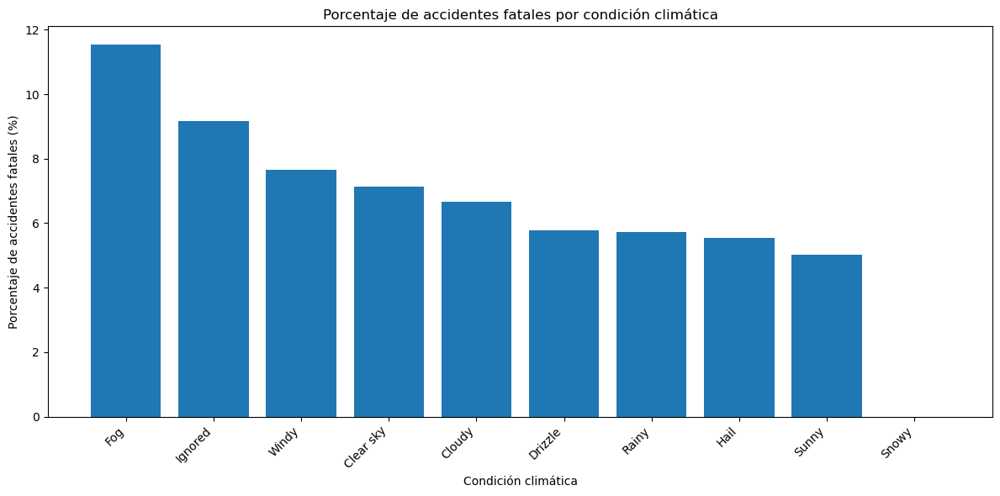

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

# Agrupar por clima
clima_severidad = (
    df
    .groupby('wheather_condition')
    .agg(
        total_accidentes=('severity', 'count'),
        accidentes_fatales=('severity', lambda x: (x == 2).sum())
    )
)

# Calcular porcentaje fatal
clima_severidad['porcentaje_fatal'] = (
    clima_severidad['accidentes_fatales']
    / clima_severidad['total_accidentes']
) * 100

# Ordenar
clima_severidad = clima_severidad.sort_values(
    by='porcentaje_fatal',
    ascending=False
)

# Mostrar tabla
print(clima_severidad)

# Graficar
plt.figure(figsize=(12,6))

plt.bar(
    clima_severidad.index,
    clima_severidad['porcentaje_fatal']
)

plt.title('Porcentaje de accidentes fatales por condición climática')
plt.xlabel('Condición climática')
plt.ylabel('Porcentaje de accidentes fatales (%)')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.savefig(
    'porcentaje_fatales_por_clima.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [42]:
import pandas as pd

# Agrupar por estado y tipo de accidente
tipo_estado = (
    df
    .groupby(['state', 'type_of_accident'])
    .size()
    .reset_index(name='cantidad')
)

# Obtener el tipo más frecuente por estado
idx = tipo_estado.groupby('state')['cantidad'].idxmax()

tipo_predominante = tipo_estado.loc[idx]

# Ordenar
tipo_predominante = tipo_predominante.sort_values(
    by='cantidad',
    ascending=False
)

print(tipo_predominante)

    state     type_of_accident  cantidad
225    MG         Run-off-road     13646
496    SC   Rear-end collision     11116
370    PR   Rear-end collision     10315
538    SP   Rear-end collision      7800
477    RS         Run-off-road      7369
391    RJ   Rear-end collision      6155
183    GO         Run-off-road      5545
267    MT         Run-off-road      4123
328    PE   Rear-end collision      3945
97     BA   Rear-end collision      3765
160    ES   Rear-end collision      3162
246    MS         Run-off-road      2635
307    PB   Rear-end collision      2273
118    CE   Rear-end collision      2162
421    RO  Broadside collision      2161
412    RN   Rear-end collision      2138
139    DF   Rear-end collision      1890
337    PI  Broadside collision      1513
202    MA   Rear-end collision      1471
286    PA   Rear-end collision      1349
36     AL         Run-off-road       792
561    TO         Run-off-road       770
517    SE   Rear-end collision       717
13     AC   Rear

C:\Users\herna\AppData\Local\Temp\ipykernel_5880\1130992670.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['state', 'type_of_accident'])
C:\Users\herna\AppData\Local\Temp\ipykernel_5880\1130992670.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  idx = tipo_estado.groupby('state')['cantidad'].idxmax()


In [43]:
tipo_predominante['state_name'] = (
    tipo_predominante['state']
    .map(estados_brasil)
)

print(
    tipo_predominante[
        ['state_name', 'type_of_accident', 'cantidad']
    ]
)

              state_name     type_of_accident  cantidad
225         Minas Gerais         Run-off-road     13646
496       Santa Catarina   Rear-end collision     11116
370               Paraná   Rear-end collision     10315
538            São Paulo   Rear-end collision      7800
477    Rio Grande do Sul         Run-off-road      7369
391       Río de Janeiro   Rear-end collision      6155
183                Goiás         Run-off-road      5545
267          Mato Grosso         Run-off-road      4123
328           Pernambuco   Rear-end collision      3945
97                 Bahía   Rear-end collision      3765
160       Espírito Santo   Rear-end collision      3162
246   Mato Grosso do Sul         Run-off-road      2635
307              Paraíba   Rear-end collision      2273
118                Ceará   Rear-end collision      2162
421             Rondônia  Broadside collision      2161
412  Rio Grande do Norte   Rear-end collision      2138
139     Distrito Federal   Rear-end collision   

In [44]:
tipo_severidad = (
    df
    .groupby('type_of_accident')
    .agg(
        total=('severity', 'count'),
        fatales=('severity', lambda x: (x == 2).sum())
    )
)

tipo_severidad['pct_fatal'] = (
    tipo_severidad['fatales']
    / tipo_severidad['total']
) * 100

tipo_severidad = tipo_severidad.sort_values(
    by='pct_fatal',
    ascending=False
)

print(tipo_severidad)

                                     total  fatales  pct_fatal
type_of_accident                                              
Pedestrian collision                 21278     5953  27.977254
Head-on collision                    30242     8441  27.911514
Side collision (opposite direction)   4727      403   8.525492
Not informed                            40        3   7.500000
Unusual events                         800       47   5.875000
Animal collision                      8424      489   5.804843
Collision with moving object          1594       83   5.207026
Collision with object                12911      655   5.073193
Run-off-road                         75549     3788   5.013964
Broadside collision                  57065     2624   4.598265
Collision with fixed object          21743      988   4.543991
Rear-end collision                   86472     3427   3.963133
Rollover                             16849      652   3.869666
Overturn                             36750     1388   3

C:\Users\herna\AppData\Local\Temp\ipykernel_5880\1086923720.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('type_of_accident')


# SHAP de XGBoost para severidad

In [50]:
# Creacion de la muestra SHAP

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_test_shap_xgb_sev = X_test.sample(
    n=10000,
    random_state=42
)

print("Muestra SHAP:", X_test_shap_xgb_sev.shape)

Muestra SHAP: (10000, 165)


In [51]:
# Calcular SHAP

explainer_xgb_sev = shap.TreeExplainer(model_xgb)

shap_values_xgb_sev = explainer_xgb_sev(
    X_test_shap_xgb_sev
)

print("Forma SHAP:")
print(shap_values_xgb_sev.shape)

Forma SHAP:
(10000, 165, 3)


In [52]:
print(shap_values_xgb_sev.shape)

(10000, 165, 3)


In [53]:
# Separacion de las 3 clases

shap_xgb_leve = shap_values_xgb_sev[:, :, 0]
shap_xgb_grave = shap_values_xgb_sev[:, :, 1]
shap_xgb_fatal = shap_values_xgb_sev[:, :, 2]

print("Leve :", shap_xgb_leve.shape)
print("Grave:", shap_xgb_grave.shape)
print("Fatal:", shap_xgb_fatal.shape)

Leve : (10000, 165)
Grave: (10000, 165)
Fatal: (10000, 165)


In [54]:
# 15 Variables mas importantes


def obtener_importancia_shap(shap_clase, nombre_clase):

    importancia = np.abs(
        shap_clase.values
    ).mean(axis=0)

    tabla = pd.DataFrame({
        'Variable': X_test_shap_xgb_sev.columns,
        'Importancia_SHAP': importancia
    })

    tabla = (
        tabla
        .sort_values(
            'Importancia_SHAP',
            ascending=False
        )
        .reset_index(drop=True)
    )

    print(f"TOP 15 - CLASE {nombre_clase}")
    display(tabla.head(15))

    return tabla

In [55]:
importancia_xgb_leve = obtener_importancia_shap(
    shap_xgb_leve,
    "LEVE"
)

importancia_xgb_grave = obtener_importancia_shap(
    shap_xgb_grave,
    "GRAVE"
)

importancia_xgb_fatal = obtener_importancia_shap(
    shap_xgb_fatal,
    "FATAL"
)

TOP 15 - CLASE LEVE


,Variable,Importancia_SHAP
0,uninjured,0.784006
1,people,0.745674
2,vehicles_involved,0.163011
3,type_of_accident_Pedestrian collision,0.135472
4,type_of_accident_Head-on collision,0.113355
5,latitude,0.096972
6,ignored,0.092163
7,road_type_Simple,0.070047
8,hour_num,0.069982
9,cause_of_accident_Incompatible velocity,0.038215


TOP 15 - CLASE GRAVE


,Variable,Importancia_SHAP
0,uninjured,0.390478
1,people,0.379357
2,ignored,0.188011
3,latitude,0.065143
4,type_of_accident_Broadside collision,0.058362
5,type_of_accident_Run-off-road,0.041528
6,longitude,0.038898
7,hour_num,0.034117
8,state_SP,0.023823
9,state_ES,0.018592


TOP 15 - CLASE FATAL


,Variable,Importancia_SHAP
0,people,0.288519
1,uninjured,0.255003
2,latitude,0.238836
3,hour_num,0.221739
4,type_of_accident_Head-on collision,0.170187
5,vehicles_involved,0.150397
6,type_of_accident_Pedestrian collision,0.139526
7,road_type_Simple,0.117265
8,longitude,0.087783
9,cause_of_accident_Incompatible velocity,0.078450


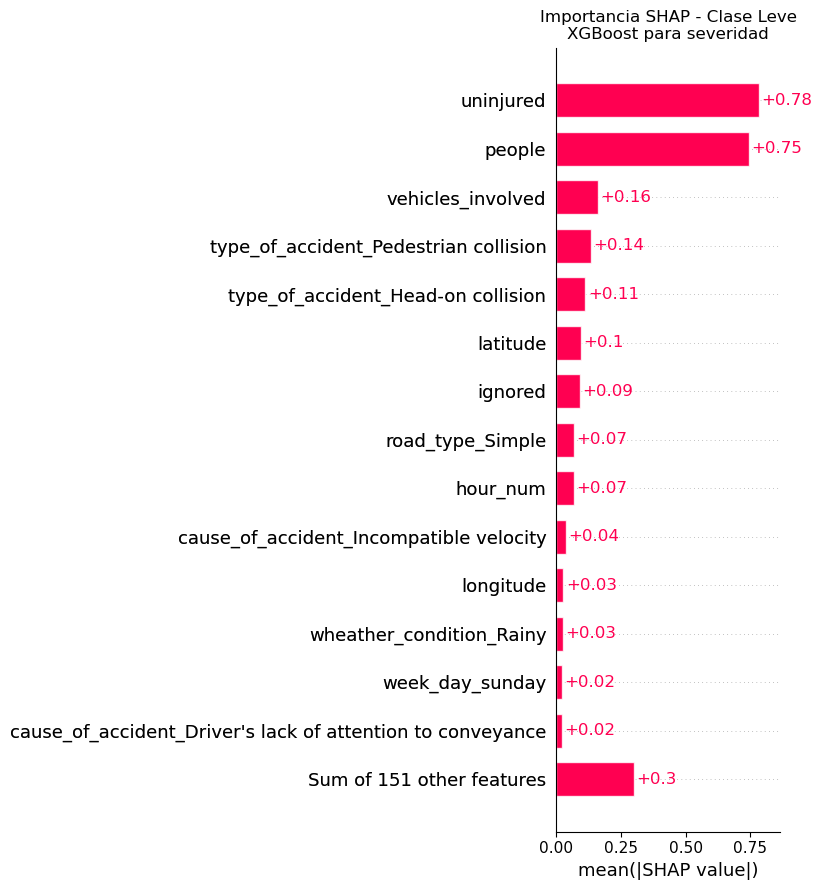

In [56]:
# Gráfico de importancia — clase leve

shap.plots.bar(
    shap_xgb_leve,
    max_display=15,
    show=False
)

plt.title(
    "Importancia SHAP - Clase Leve\n"
    "XGBoost para severidad"
)

plt.tight_layout()

plt.savefig(
    "SHAP_XGBoost_Severidad_Leve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

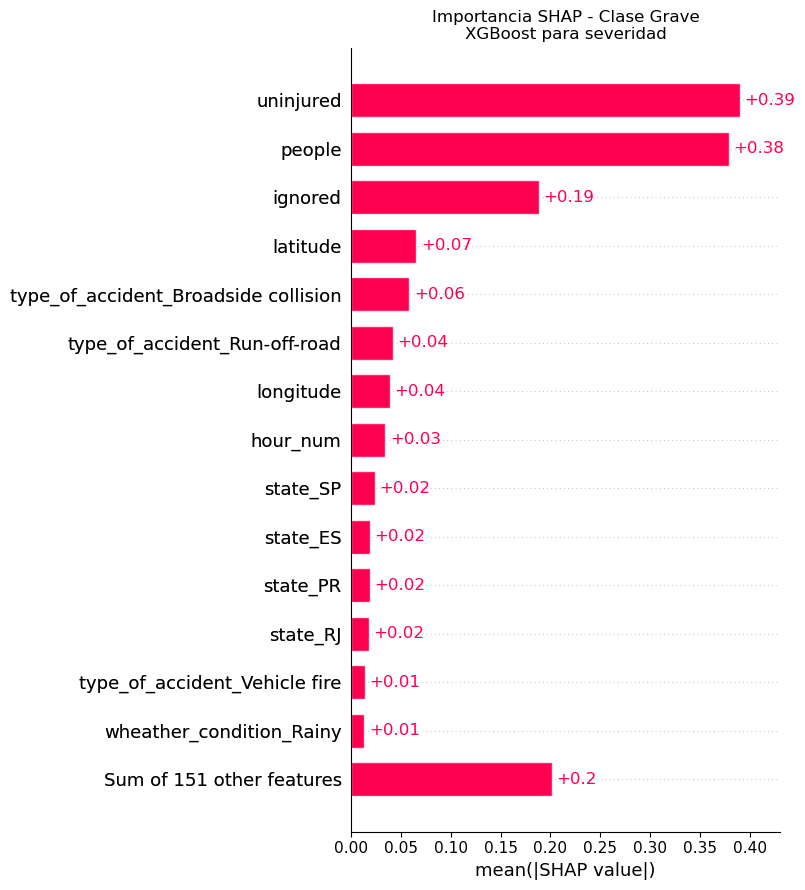

In [57]:
# 4. Gráfico de importancia — clase grave

shap.plots.bar(
    shap_xgb_grave,
    max_display=15,
    show=False
)

plt.title(
    "Importancia SHAP - Clase Grave\n"
    "XGBoost para severidad"
)

plt.tight_layout()

plt.savefig(
    "SHAP_XGBoost_Severidad_Grave.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


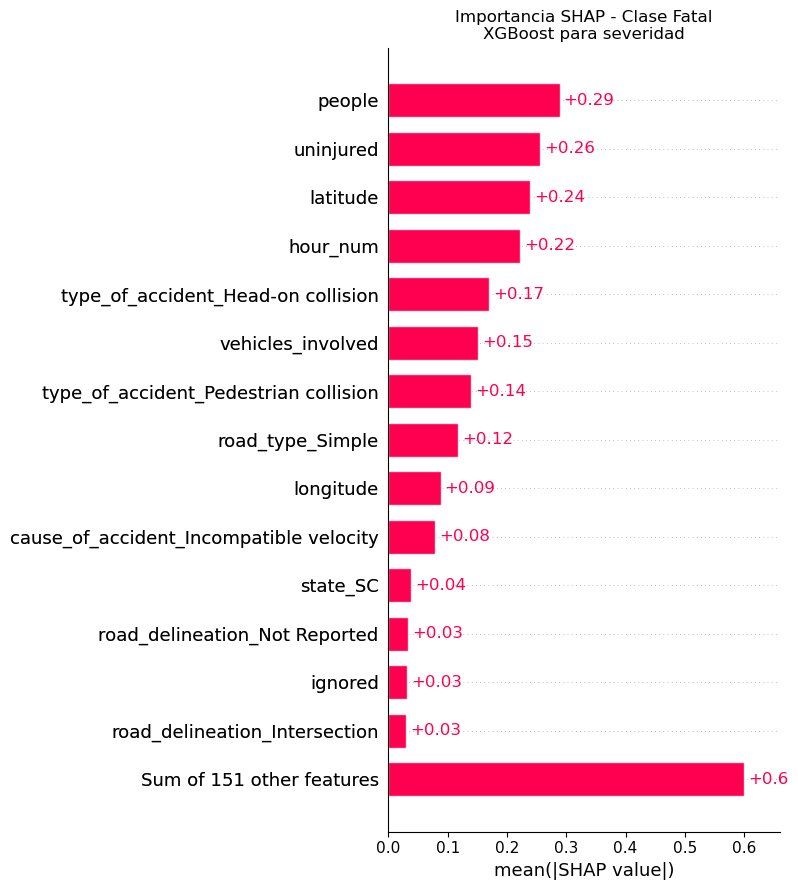

In [58]:
# 5. Gráfico de importancia — clase fatal

shap.plots.bar(
    shap_xgb_fatal,
    max_display=15,
    show=False
)

plt.title(
    "Importancia SHAP - Clase Fatal\n"
    "XGBoost para severidad"
)

plt.tight_layout()

plt.savefig(
    "SHAP_XGBoost_Severidad_Fatal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

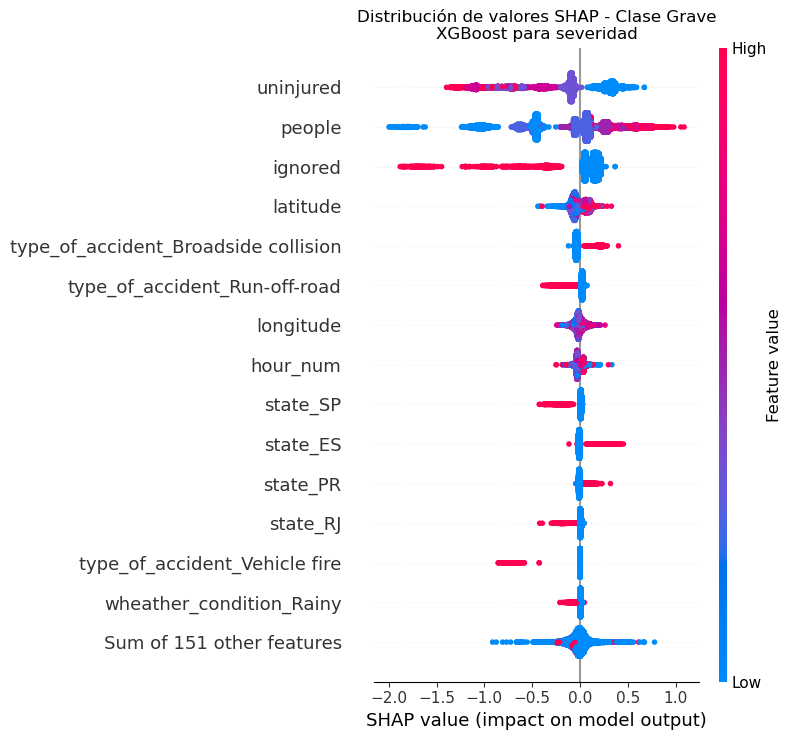

In [59]:
# 6. Beeswarm de la clase grave

shap.plots.beeswarm(
    shap_xgb_grave,
    max_display=15,
    show=False
)

plt.title(
    "Distribución de valores SHAP - Clase Grave\n"
    "XGBoost para severidad"
)

plt.tight_layout()

plt.savefig(
    "SHAP_XGBoost_Severidad_Grave_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()